# Student Performance Analysis

Explore exam scores and group differences with Pandas and Matplotlib. Run cells in order with `data/student_performance.csv` available.

**Data source:** [Kaggle — spscientist/students-performance-in-exams](https://www.kaggle.com/datasets/spscientist/students-performance-in-exams). See `../data/README.md` for download instructions.

In [1]:
from pathlib import Path

# Support execution from the project root or notebooks directory.
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "student_performance.csv"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

df = pd.read_csv(DATA_PATH)

## Data quality

Check missing values and exact duplicate rows before interpreting the analysis. Duplicates are reported rather than automatically removed.

In [2]:
print("Rows and columns:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
display(df.isna().sum().rename("missing_values").to_frame())

Rows and columns: (1000, 8)
Duplicate rows: 0


,missing_values
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


## 1. Inspect the data

Review columns, types, and category values before comparing scores.

In [3]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [5]:
for c in df.columns:
    print(c,': ' ,df[c].unique())

gender :  <StringArray>
['female', 'male']
Length: 2, dtype: str
race/ethnicity :  <StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str
parental level of education :  <StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str
lunch :  <StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
test preparation course :  <StringArray>
['none', 'completed']
Length: 2, dtype: str
math score :  [ 72  69  90  47  76  71  88  40  64  38  58  65  78  50  18  46  54  66
  44  74  73  67  70  62  63  56  97  81  75  57  55  53  59  82  77  33
  52   0  79  39  45  60  61  41  49  30  80  42  27  43  68  85  98  87
  51  99  84  91  83  89  22 100  96  94  48  35  34  86  92  37  28  24
  26  95  36  29  32  93  19  23   8]
reading score :  [ 72  90  95  57  78  83  43  64  60  54  52  81  53  75  89  32  42  58
  69  73  71  74  70  65  87  5

## 2. Score distributions

Use the mean of math, reading, and writing scores as the overall score. Compare its distribution across groups.

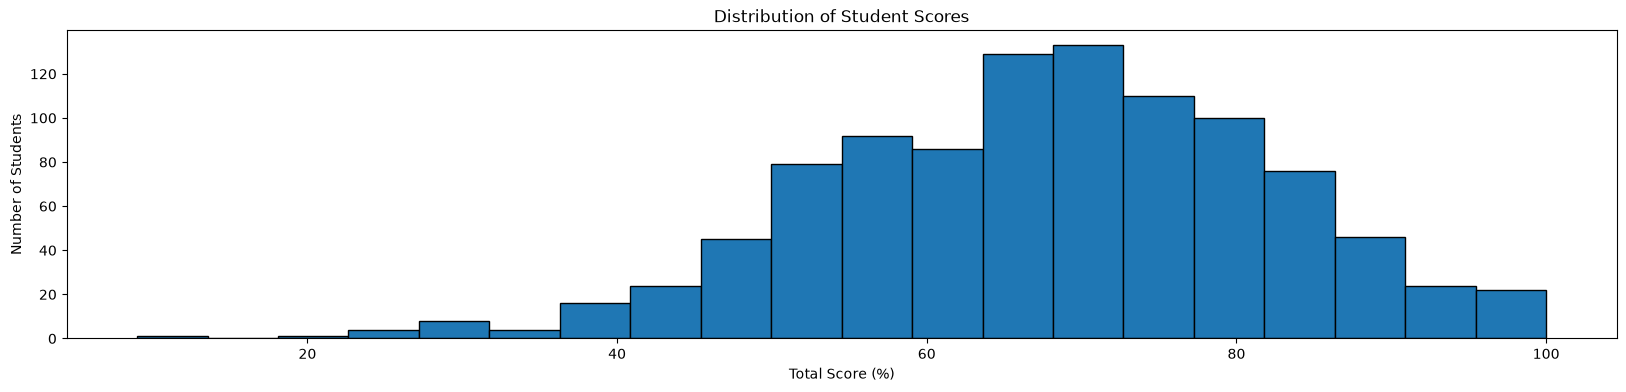

In [6]:
df['total score'] = (df['math score'] + df['writing score'] + df['reading score'])/3
df['total score'].plot(
    kind='hist',
    bins=20,
    figsize=(20, 4),
    edgecolor='black'
)

plt.xlabel('Total Score (%)')
plt.ylabel('Number of Students')
plt.title('Distribution of Student Scores')
plt.show()

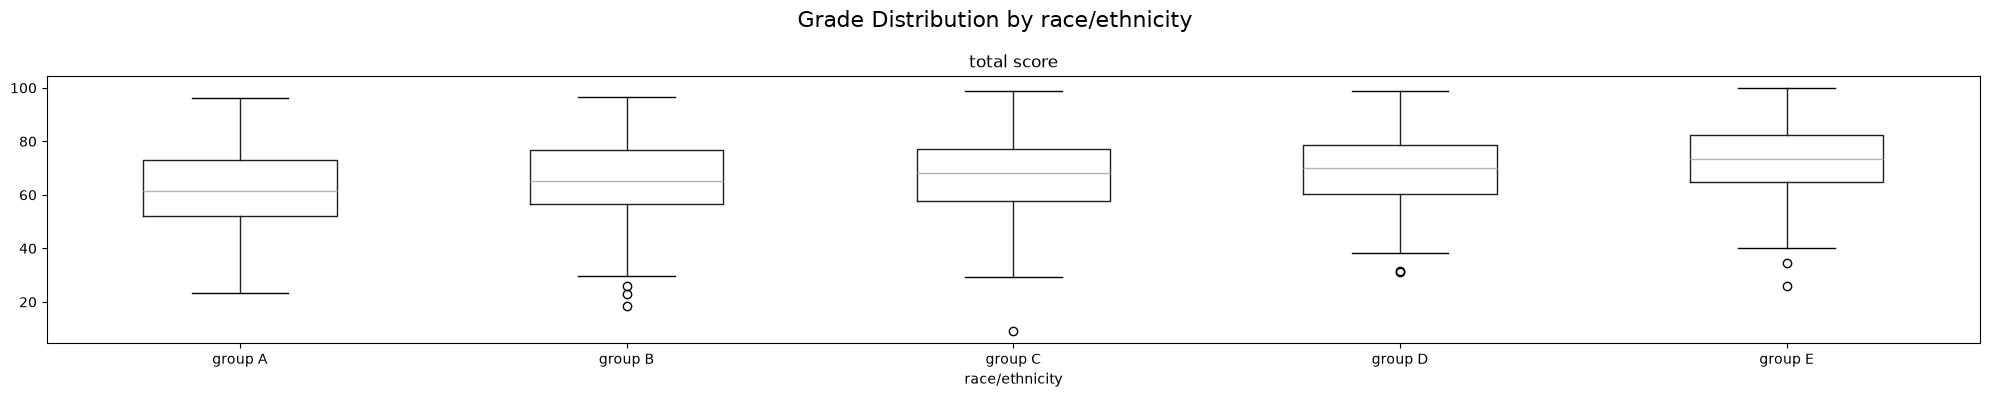

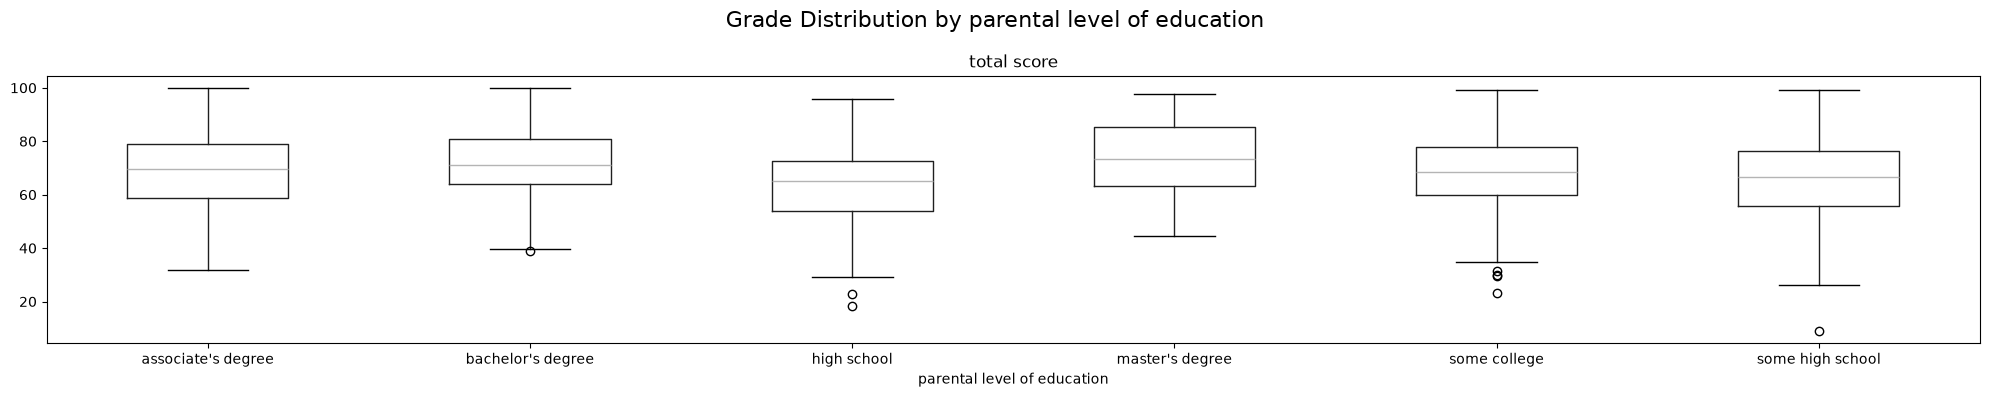

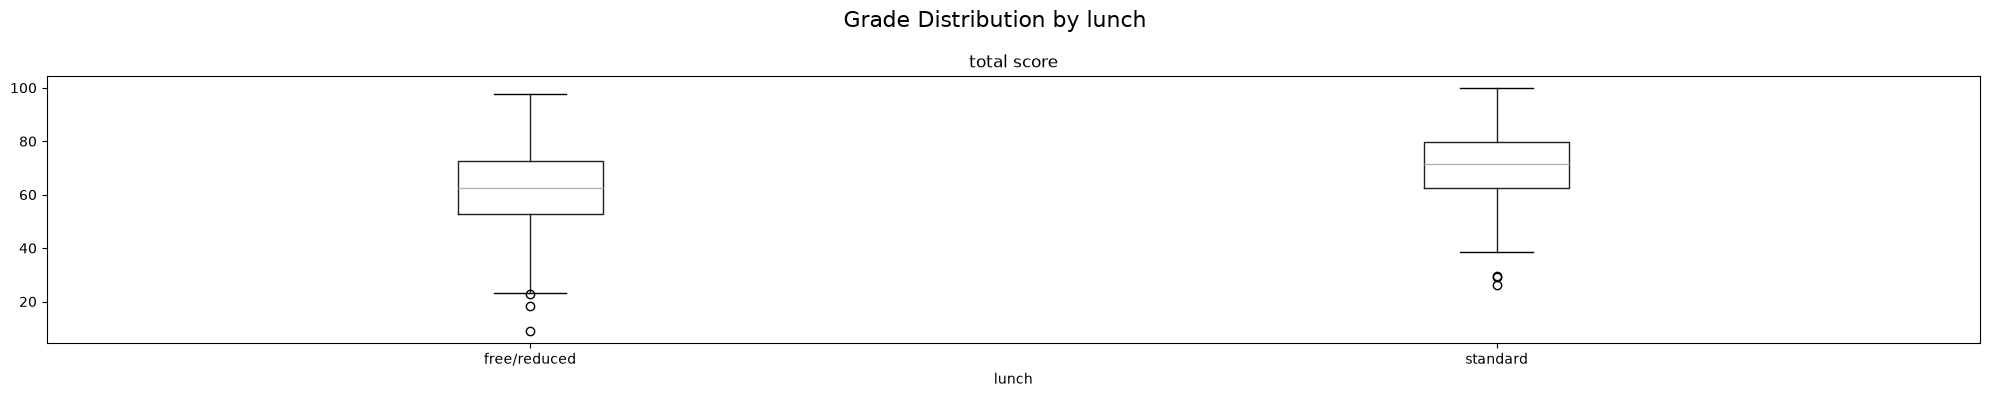

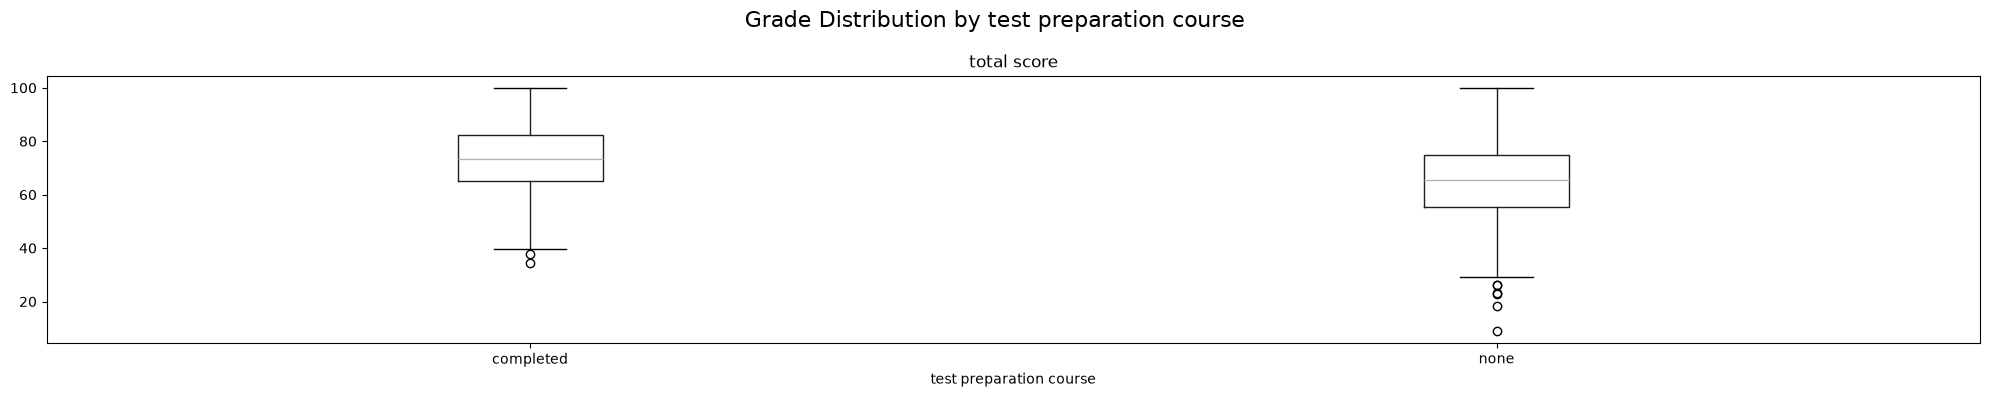

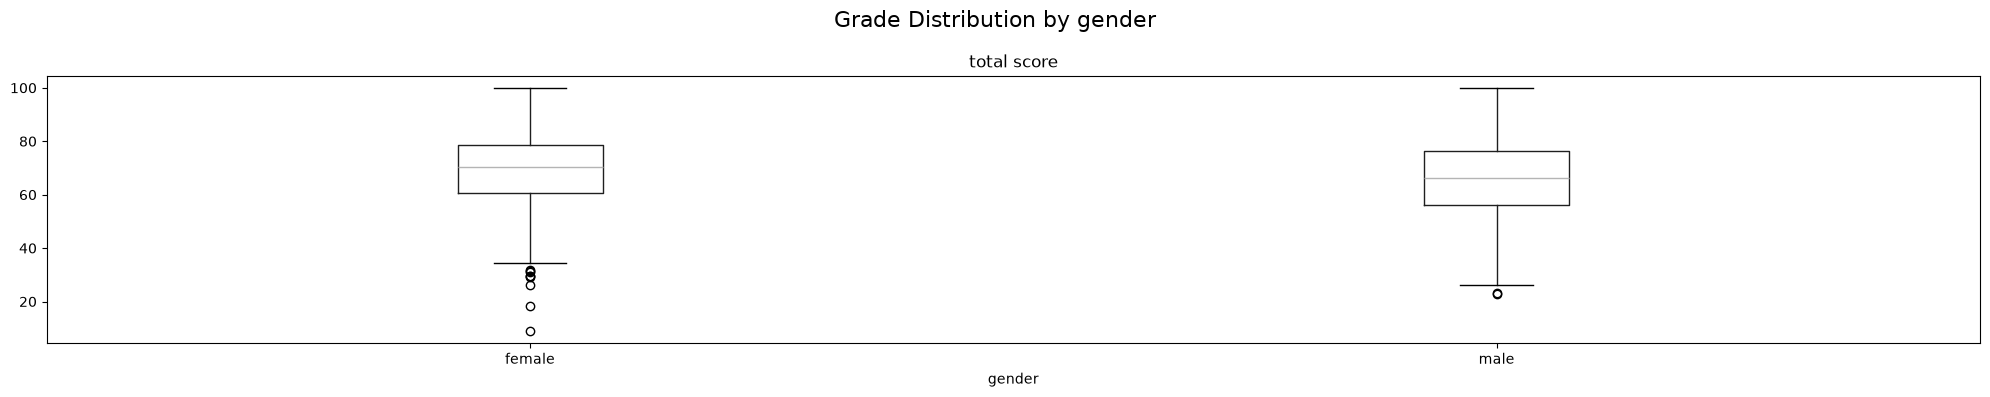

In [7]:
group_columns = [ 'race/ethnicity',  'parental level of education', 'lunch', 'test preparation course','gender']
for col in group_columns:
    axes = df.boxplot(
        column='total score',
        by=col,
        figsize=(20,4),
        grid=False
    )
    plt.suptitle(f'Grade Distribution by {col}', fontsize=16)
    plt.tight_layout()
    plt.show()

### Observations

Completed preparation and standard lunch are associated with higher median overall scores. Group distributions overlap substantially. These descriptive comparisons do not establish causality.

## 3. High- and low-score rates

Compare the share of students with an overall score above 80 or below 40 within each group.

In [8]:
group_columns = [
    'race/ethnicity',
    'parental level of education',
    'lunch',
    'test preparation course',
    'gender'
]

for col in group_columns:
    result = (
        df.assign(high_scorer=df['total score'] > 80)
        .groupby(col)['high_scorer']
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    print(result.round(2))
print("Opposite")
for col in group_columns:
    result = (
        df.assign(low_scorer=df['total score'] < 40)
        .groupby(col)['low_scorer']
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    print(result.round(2))

race/ethnicity
group E    30.71
group D    20.23
group B    17.89
group C    16.93
group A    11.24
Name: high_scorer, dtype: float64
parental level of education
master's degree       33.90
bachelor's degree     26.27
associate's degree    22.97
some college          19.47
some high school      16.76
high school            9.18
Name: high_scorer, dtype: float64
lunch
standard        24.34
free/reduced    10.42
Name: high_scorer, dtype: float64
test preparation course
completed    29.33
none         13.86
Name: high_scorer, dtype: float64
gender
female    22.20
male      16.39
Name: high_scorer, dtype: float64
Opposite
race/ethnicity
group B    4.21
group A    3.37
group C    3.13
group D    2.67
group E    1.43
Name: low_scorer, dtype: float64
parental level of education
some high school      5.59
high school           5.10
some college          2.65
bachelor's degree     1.69
associate's degree    0.90
master's degree       0.00
Name: low_scorer, dtype: float64
lunch
free/reduced    6

## Key findings

- High-score rates: 29.33% with completed preparation versus 13.86% without.
- Standard-lunch students have higher high-score rates (24.34% versus 10.42%).
- High-score rates vary across parental education and other recorded groups.

**Next:** examine group sizes and uncertainty before drawing stronger conclusions.